🌳 Identify Spatial Neighbourhoods on Categorical Data (cell phenotypes)

In [1]:
# import packages
import scimap as sm
import anndata as ad
# Load the data that we saved in the last tutorial (with ROIs added)
adata = ad.read_h5ad(r'C:\Users\chuab\Desktop\SciMap_project\scimapExampleData\scimapExampleData.h5ad')

Running SCIMAP  2.3.5


c:\Users\chuab\anaconda3\envs\scimap\lib\site-packages\mpl_scatter_density\__init__.py:4: UserWarning:

pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.

c:\Users\chuab\anaconda3\envs\scimap\lib\site-packages\tqdm\auto.py:21: TqdmWarning:

IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html



A. spatial_count approach

In [2]:
adata = sm.tl.spatial_count(adata, phenotype='leiden_phenotype', method='radius', radius=80, label='spatial_count')
# note that the df_name parameter needs to the same as the label used in the previous step.
adata = sm.tl.spatial_cluster(adata, df_name='spatial_count', method='kmeans', k=6, label='neigh_kmeans')

Identifying neighbours within 80 pixels of every cell
Kmeans clustering


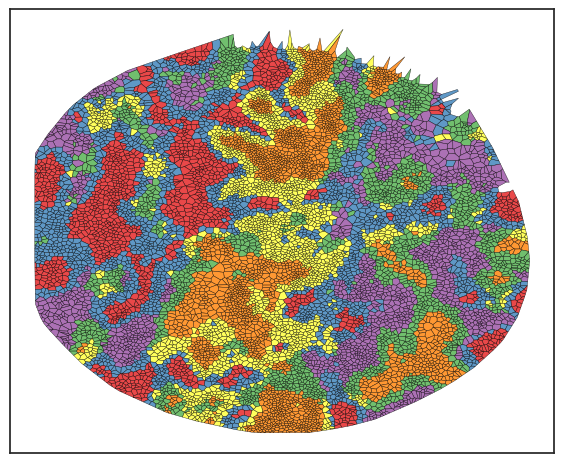

In [3]:
# Let's visualize the results.
sm.pl.voronoi(adata, color_by='neigh_kmeans', 
                 voronoi_edge_color = 'black',
                 voronoi_line_width = 0.3, 
                 voronoi_alpha = 0.8, 
                 size_max=3000,
                 overlay_points=None, 
                 plot_legend=True, 
                 legend_size=6)

Typically, we over-cluster the data and then group them into meta clusters. This approach helps ensure that no rare clusters are missed. To understand these neighborhoods, examine the cell type composition within each one. When analyzing solid tumors, you'll often find a tumor neighborhood dominated by tumor cells, usually over 90%, and a tumor-stromal interface neighborhood that features a mix of tumor and stromal cells.

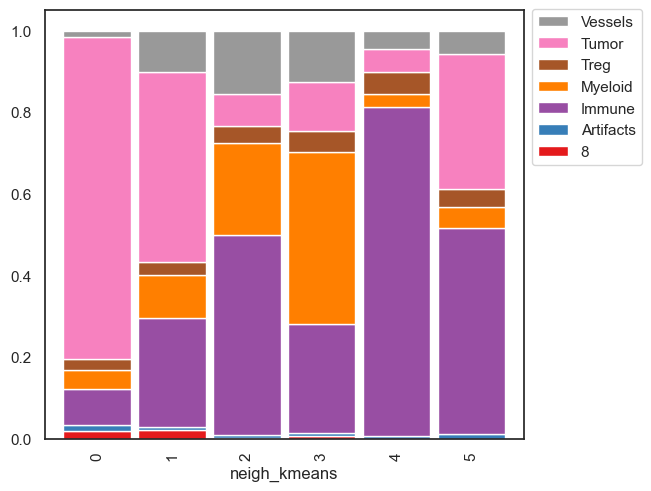

In [4]:
# Let's plot the composition of these neighbourhoods
sm.pl.stacked_barplot (adata, x_axis='neigh_kmeans', y_axis='leiden_phenotype')

While analyzing the clusters, the cell type distribution allows us to name each neighborhood. Naming 30 or 40 clusters can be challenging. Therefore, there are different strategies for grouping them into meta clusters:

1. Use Plotly to create stacked bar plots, which offer added interactivity. This feature lets you toggle specific cell types on and off to examine their distribution across neighborhoods.
2. I also utilize Plotly for spatial scatter plots, adding another layer of interactivity. This helps in understanding distribution based on known histology. For example, if a cluster is localized to the skin's upper layer, it likely represents a structural unit like the epidermis. Note that while scimap doesn't natively support spatial scatter plots in Plotly, I'll share a script that enables this functionality.
3. Additionally, I analyze the correlation of cell type abundance across neighborhoods, aiding in grouping similar clusters together.

1. stacked bar plot with plotly

In [5]:
# you will notice that the execution of this line will open a new tab in your web browser with the plot
sm.pl.stacked_barplot (adata, x_axis='neigh_kmeans', y_axis='leiden_phenotype', plot_tool='plotly')

2. spatial scatter plot with plotly

In [6]:
# Vizualising using plotly
import pandas as pd
import plotly.express as px
import plotly.io as pio

def plotly (adata,phenotype,image_id=None,x='X_centroid',y='Y_centroid',size=2, **kwargs):
    if image_id is not None:
        adata = adata[adata.obs['imageid'] == image_id]    
    data = pd.DataFrame({'x':adata.obs[x], 'y':adata.obs[y],'col': adata.obs[phenotype]})
    data = data.sort_values(by=['col'])
    fig = px.scatter(data, x="x", y="y", color="col", **kwargs)
    fig.update_traces(marker=dict(size=size),selector=dict(mode='markers'),hoverlabel = dict(namelength = -1))
    fig.update_yaxes(autorange="reversed", tickformat='g')
    fig.update_xaxes(tickformat='g')
    fig.update_layout({'plot_bgcolor': 'rgba(0, 0, 0, 0)','paper_bgcolor': 'rgba(0, 0, 0, 0)'})
    fig.show()

In [7]:
# you will notice that the execution of this line will open a new tab in your web browser with the plot
plotly (adata,phenotype='neigh_kmeans', size=8)

3. Correlation plot to check which clusters are similar

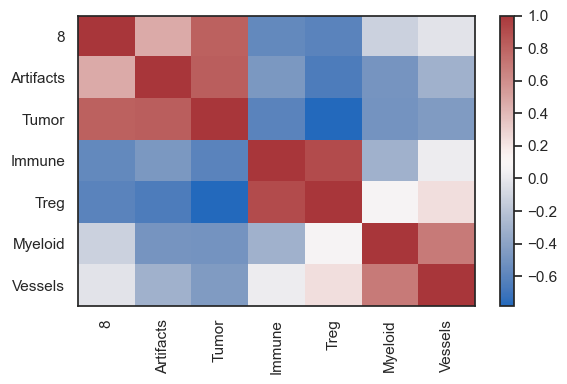

In [8]:
sm.pl.groupCorrelation(adata, groupBy='leiden_phenotype', condition='neigh_kmeans', figsize=(6,4))

In [9]:
# After deciding which clusters to group together, use the rename function to add a new column that represents the consolidated neighborhoods.
# Consolidate clusters to neighborhoods

rename_dict = {'RCN1': ['1'],
               'RCN2': ['0', '4'],
                'RCN3': ['2'],
                'RCN4': ['3']}

adata = sm.hl.rename(adata, rename=rename_dict, from_column='neigh_kmeans', to_column='RCNs')

Renaming 1 to RCN1
Renaming 0 to RCN2
Renaming 4 to RCN2
Renaming 2 to RCN3
Renaming 3 to RCN4


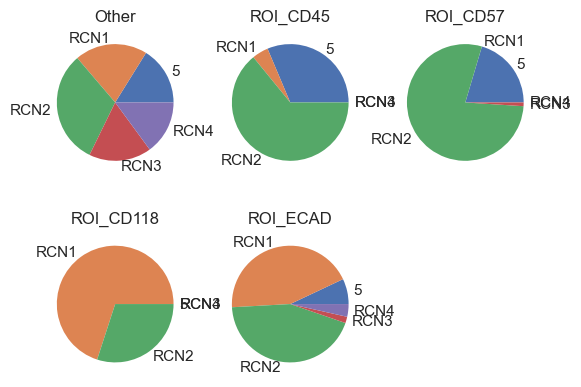

In [10]:
# Visualize the RCNs composition between patient groups (in this case ROIs as example)

sm.pl.pie(adata, phenotype='RCNs', group_by='ROI', ncols=3)

B. spatial_lda approach

The "sm.tl.spatial_lda" function constructs a neighborhood matrix using categorical variables, such as cell types, designated by the user. It applies Latent Dirichlet Allocation (LDA) to explore the latent architecture of cellular distributions. This methodology produces weights that clarify the spatial configuration of cells, thus facilitating the identification of Recurrent Cellular Neighborhoods (RCNs). Generally, LDA is utilized for text data, aiming to cluster documents based on the frequency of word usage. It's important to note that, in contrast to text data, which may contain millions of unique words, our scenario typically involves a much smaller vocabulary—often between 5 to 20 cell types. This limited "vocabulary" can prevent the LDA model from converging. Therefore, rather than directly using the output of the LDA model, we extract latent variables post-training and cluster these to define cellular neighborhoods. This approach adapts the LDA model, commonly used for text, to effectively analyze cellular spatial distributions.

In [ ]:
# run the LDA tool
adata = sm.tl.spatial_lda(adata, phenotype='leiden_phenotype', method='radius', radius=30, label='spatial_lda') # computationally intensive, adjust radius.
# note that the df_name parameter needs to be the same as the label used in the previous step.
adata = sm.tl.spatial_cluster(adata, phenotype='leiden_phenotype', df_name='spatial_lda', method='kmeans', k=6, label='spatial_lda_kmeans')

NameError: name 'sm' is not defined

In [ ]:
# Let's visualize the results.
sm.pl.voronoi(adata, color_by='spatial_lda_kmeans', 
                 voronoi_edge_color = 'black',
                 voronoi_line_width = 0.3, 
                 voronoi_alpha = 0.8, 
                 size_max=3000,
                 overlay_points=None, 
                 plot_legend=True, 
                 legend_size=6)

In [ ]:
# Save the results
adata.write('C:\\Users\\chuab\\Desktop\\SciMap_project\\scimapExampleData\\scimapExampleData.h5ad')